# Assignments: Cleaning Data

## 1. Data in Python Request

* Read in data from the Excel spreadsheet (Alarm Survey Data.xlsx) and put into a Pandas DataFrame
* Check the data type of each column
* Convert object columns into numeric or datetime columns, as needed

In [1]:
import pandas as pd
import os

In [2]:
data_folder = r'D:\Study\Data Engineering and Analytics\Data Engineering with Pandas - Udemy\Data+Science+in+Python+-+Data+Prep+&+EDA\Data'
file_name = 'Alarm Survey Data.xlsx'
file = data_folder + r'\\' + file_name

In [3]:
df_alarm_survey = pd.read_excel(file)

In [4]:
df_alarm_survey.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   survey_id           6433 non-null   int64  
 1   age                 6433 non-null   int64  
 2   number_of_children  6433 non-null   float64
 3   activity_level      6433 non-null   str    
 4   sleep_quality       6082 non-null   float64
 5   number_of_snoozes   6433 non-null   int64  
 6   alarm_rating        6433 non-null   str    
dtypes: float64(2), int64(3), str(2)
memory usage: 459.8 KB


In [5]:
df_alarm_survey.head(3)

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
0,1,34,3.0,active,3.0,1,5 stars
1,2,31,3.0,light,3.0,3,3 stars
2,3,18,0.0,light_activity,4.0,1,1 stars


In [6]:
df_alarm_survey.dtypes

survey_id               int64
age                     int64
number_of_children    float64
activity_level            str
sleep_quality         float64
number_of_snoozes       int64
alarm_rating              str
dtype: object

In [7]:
#df_alarm_survey['number_of_children'] = df_alarm_survey['number_of_children'].astype('int')
#Takes care of the Non Finite Values first
#df_alarm_survey['sleep_quality'] = df_alarm_survey['sleep_quality'].fillna(0).astype('int')
#Another approach
df_alarm_survey['number_of_children'] = pd.to_numeric(df_alarm_survey['number_of_children'], errors='coerce', downcast='integer').astype('int')
#df_alarm_survey['sleep_quality'] = pd.to_numeric(df_alarm_survey['sleep_quality'].fillna(0), errors='coerce', downcast='integer').astype('int')
#Cast to str
df_alarm_survey['activity_level'] = df_alarm_survey['activity_level'].astype("str")
#Cast to int after removing space stars
df_alarm_survey['alarm_rating'] = pd.to_numeric(df_alarm_survey['alarm_rating'].str.replace(' stars', ''))

In [8]:
df_alarm_survey.dtypes

survey_id               int64
age                     int64
number_of_children      int64
activity_level            str
sleep_quality         float64
number_of_snoozes       int64
alarm_rating            int64
dtype: object

In [9]:
df_alarm_survey.head(2)

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
0,1,34,3,active,3.0,1,5
1,2,31,3,light,3.0,3,3


In [10]:
df_alarm_survey.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   survey_id           6433 non-null   int64  
 1   age                 6433 non-null   int64  
 2   number_of_children  6433 non-null   int64  
 3   activity_level      6433 non-null   str    
 4   sleep_quality       6082 non-null   float64
 5   number_of_snoozes   6433 non-null   int64  
 6   alarm_rating        6433 non-null   int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 415.8 KB


In [11]:
df_alarm_survey[df_alarm_survey.isna().any(axis=1)]


,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
10,11,28,2,light_activity,NaN,3,4
18,19,38,2,lightly active,NaN,1,5
23,24,24,2,very active,NaN,1,5
26,27,25,2,lightly active,NaN,1,2
28,29,29,2,lightly active,NaN,1,2
...,...,...,...,...,...,...,...
6310,6311,30,2,very active,NaN,0,3
6319,6320,44,2,lightly active,NaN,0,3
6375,6309,32,3,light,NaN,0,3
6377,6311,30,2,very active,NaN,0,3


## 2. Missing Data Check

* Find any missing data
* Deal with the missing data

In [12]:
#Checks for missing values
df_alarm_survey[df_alarm_survey.isna().any(axis=1)]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
10,11,28,2,light_activity,NaN,3,4
18,19,38,2,lightly active,NaN,1,5
23,24,24,2,very active,NaN,1,5
26,27,25,2,lightly active,NaN,1,2
28,29,29,2,lightly active,NaN,1,2
...,...,...,...,...,...,...,...
6310,6311,30,2,very active,NaN,0,3
6319,6320,44,2,lightly active,NaN,0,3
6375,6309,32,3,light,NaN,0,3
6377,6311,30,2,very active,NaN,0,3


In [13]:
#Shows all the unique values in the column, dropna false ensures it will show NaN as well
df_alarm_survey['sleep_quality'].value_counts(dropna=False)

sleep_quality
5.0    2721
4.0    2261
3.0     997
NaN     351
1.0     103
Name: count, dtype: int64

In [14]:
#Fill in the values in NaN with the number 2 as it is missing
df_alarm_survey['sleep_quality'] = df_alarm_survey['sleep_quality'].fillna(2)

In [15]:
df_alarm_survey['sleep_quality'].value_counts(dropna=False)

sleep_quality
5.0    2721
4.0    2261
3.0     997
2.0     351
1.0     103
Name: count, dtype: int64

In [16]:
df_alarm_survey.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   survey_id           6433 non-null   int64  
 1   age                 6433 non-null   int64  
 2   number_of_children  6433 non-null   int64  
 3   activity_level      6433 non-null   str    
 4   sleep_quality       6433 non-null   float64
 5   number_of_snoozes   6433 non-null   int64  
 6   alarm_rating        6433 non-null   int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 415.8 KB


## 3. Inconsistent Text & Typos Check

* Find any inconsistent text and typos
* Deal with the inconsistent text and typos

In [17]:
df_alarm_survey.head(5)

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
0,1,34,3,active,3.0,1,5
1,2,31,3,light,3.0,3,3
2,3,18,0,light_activity,4.0,1,1
3,4,42,4,active,4.0,1,4
4,5,30,1,light_activity,1.0,4,3


In [18]:
df_alarm_survey['activity_level'].value_counts(dropna=False)

activity_level
active            2450
lightly active    2289
light_activity     691
very active        669
light              334
Name: count, dtype: int64

In [19]:
#Solution mapping the values
# map_activity_level = {
#     'active':'active',
#     'lightly active':'lightly active',
#     'light_activity':'lightly active',
#     'light':'lightly active',
#     'active':'active',
#     'very active':'very active'
#                           }

In [20]:
#df_alarm_survey['activity_level'] = df_alarm_survey['activity_level'].map(map_activity_level)

In [21]:
#Solution using np.where achieving the same thing as map
import numpy as np

In [22]:
df_alarm_survey['activity_level'] = np.where(df_alarm_survey['activity_level'].isin(['light', 'light_activity', 'lightly active']), 'light activity', df_alarm_survey['activity_level'])

In [23]:
df_alarm_survey['activity_level'].value_counts(dropna=False)

activity_level
light activity    3314
active            2450
very active        669
Name: count, dtype: int64

In [24]:
df_alarm_survey.head(5)

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
0,1,34,3,active,3.0,1,5
1,2,31,3,light activity,3.0,3,3
2,3,18,0,light activity,4.0,1,1
3,4,42,4,active,4.0,1,4
4,5,30,1,light activity,1.0,4,3


In [25]:
df_alarm_survey.describe()

,survey_id,age,number_of_children,sleep_quality,number_of_snoozes,alarm_rating
count,6433.000000,6433.000000,6433.000000,6433.000000,6433.000000,6433.000000
mean,3216.302192,29.069175,1.379761,4.110835,1.145811,2.955075
std,1856.007409,7.472048,1.388768,0.963415,1.599481,1.101363
min,1.000000,13.000000,0.000000,1.000000,0.000000,1.000000
25%,1609.000000,23.000000,0.000000,4.000000,0.000000,2.000000
50%,3217.000000,28.000000,1.000000,4.000000,0.000000,3.000000
75%,4825.000000,34.000000,2.000000,5.000000,2.000000,4.000000
max,6366.000000,47.000000,5.000000,5.000000,19.000000,5.000000


## 4. Duplicate Data Check

* Find any duplicate data
* Deal with the duplicate data

In [26]:
df_alarm_survey.head(5)

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
0,1,34,3,active,3.0,1,5
1,2,31,3,light activity,3.0,3,3
2,3,18,0,light activity,4.0,1,1
3,4,42,4,active,4.0,1,4
4,5,30,1,light activity,1.0,4,3


In [27]:
#Keep=False shows everything, without it it shows the first or last duplication of the row
df_alarm_survey[df_alarm_survey.duplicated()]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
6366,6300,31,2,active,5.0,0,3
6367,6301,27,2,light activity,4.0,0,2
6368,6302,41,3,light activity,5.0,0,2
6369,6303,25,0,light activity,5.0,0,5
6370,6304,25,1,light activity,5.0,0,2
...,...,...,...,...,...,...,...
6428,6362,27,2,active,5.0,0,5
6429,6363,31,1,light activity,4.0,0,4
6430,6364,26,0,light activity,5.0,0,3
6431,6365,27,1,active,5.0,0,3


In [28]:
df_alarm_survey.drop_duplicates(inplace=True)

In [29]:
#If empty, it worked!
df_alarm_survey[df_alarm_survey.duplicated()]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating


## 5. Outliers Check

* Find any outliers
* Deal with the outliers

In [30]:
#Histogram plot, Box plot, Standard Deviation

In [31]:
#Histogram
import seaborn as sns

<Axes: xlabel='age', ylabel='Count'>

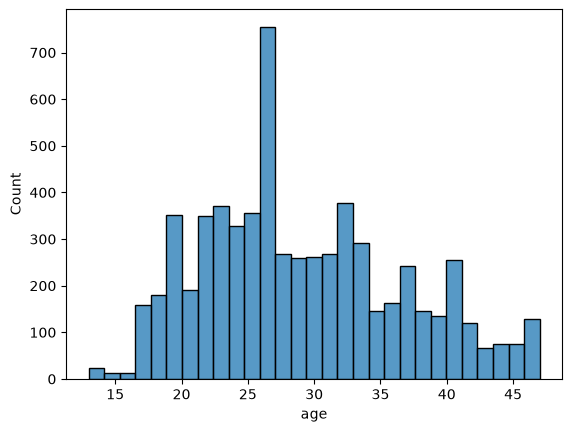

In [32]:
sns.histplot(df_alarm_survey['age'])

<Axes: xlabel='number_of_snoozes', ylabel='Count'>

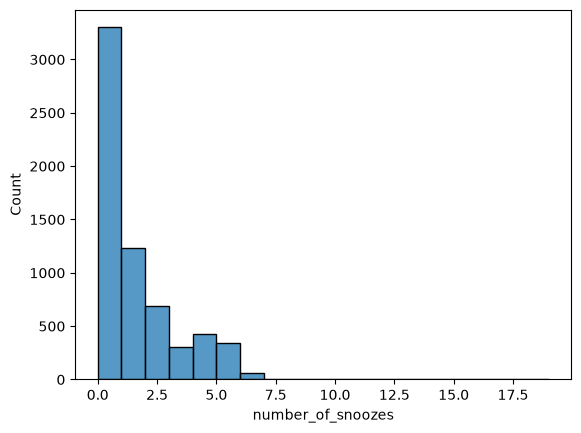

In [33]:
max_snooze = df_alarm_survey['number_of_snoozes'].max()
min_snooze = df_alarm_survey['number_of_snoozes'].min()
bin_size_snooze = max_snooze - min_snooze

sns.histplot(df_alarm_survey['number_of_snoozes'], bins=bin_size_snooze)

In [34]:
#Remove the outlier
df_alarm_survey['number_of_snoozes'].value_counts()

number_of_snoozes
0     3300
1     1229
2      693
4      427
5      345
3      309
6       59
8        2
19       1
7        1
Name: count, dtype: int64

In [35]:
#Remove 19
df_alarm_survey = df_alarm_survey[df_alarm_survey.number_of_snoozes < 19] 

In [36]:
df_alarm_survey['number_of_snoozes'].value_counts()

number_of_snoozes
0    3300
1    1229
2     693
4     427
5     345
3     309
6      59
8       2
7       1
Name: count, dtype: int64

<Axes: ylabel='number_of_snoozes'>

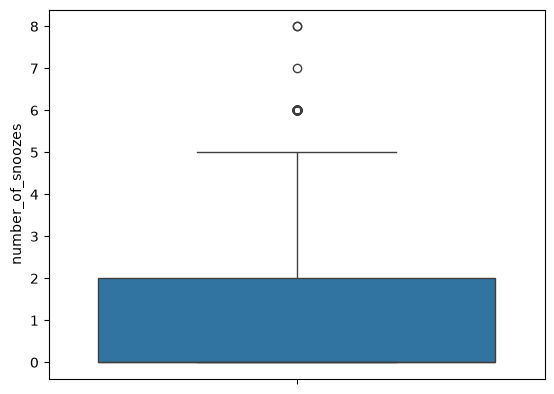

In [37]:
sns.boxplot(df_alarm_survey['number_of_snoozes'])

<Axes: ylabel='age'>

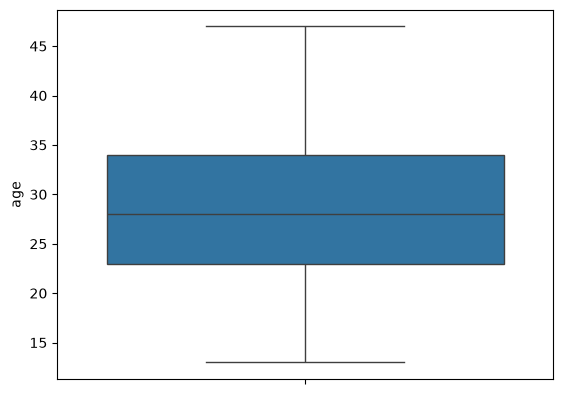

In [38]:
#Boxplot
sns.boxplot(df_alarm_survey['age'])

In [39]:
#Standard Deviation, used for normal distributions or bell curves
std_age = np.std(df_alarm_survey['age'])
mean_age = df_alarm_survey['age'].mean()

In [40]:
df_alarm_survey[df_alarm_survey['age'] < mean_age - std_age * 3]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating


In [41]:
df_alarm_survey[df_alarm_survey['age'] > mean_age + std_age * 3]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating


In [42]:
std_snoozes = np.std(df_alarm_survey['number_of_snoozes'])
mean_snoozes = df_alarm_survey['number_of_snoozes'].mean()

In [43]:
mean_snoozes, std_snoozes

(np.float64(1.1550667714061273), np.float64(1.5878539913911391))

In [44]:
negative_outliers_snoozes = df_alarm_survey[df_alarm_survey['number_of_snoozes'] < mean_snoozes - std_snoozes * 3]

In [45]:
positive_outliers_snoozers = df_alarm_survey[df_alarm_survey['number_of_snoozes'] > mean_snoozes + std_snoozes * 3]

In [46]:
positive_outliers_snoozers.number_of_snoozes.value_counts()

number_of_snoozes
6    59
8     2
7     1
Name: count, dtype: int64

In [47]:
list_snooze_outliers = [snooze for snooze in df_alarm_survey['number_of_snoozes'] if (snooze < mean_snoozes - std_snoozes * 3) or (snooze > mean_snoozes + std_snoozes * 3)]

In [48]:
set(list_snooze_outliers)

{6, 7, 8}

In [49]:
df_alarm_survey['number_of_snoozes'].value_counts().sort_index() #sort_values() for values

number_of_snoozes
0    3300
1    1229
2     693
3     309
4     427
5     345
6      59
7       1
8       2
Name: count, dtype: int64

## 6. Data Issues Check

* Quickly explore the updated DataFrame. How do things look now after handling the data issues compared to the original DataFrame?

In [50]:
#Check for missing values
df_alarm_survey[df_alarm_survey.isna().any(axis=1)]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating


In [51]:
#Check for inconsistent text
df_alarm_survey['activity_level'].value_counts()

activity_level
light activity    3287
active            2422
very active        656
Name: count, dtype: int64

In [52]:
#Check for duplicate values
df_alarm_survey[df_alarm_survey.duplicated()]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating


<Axes: xlabel='age', ylabel='Count'>

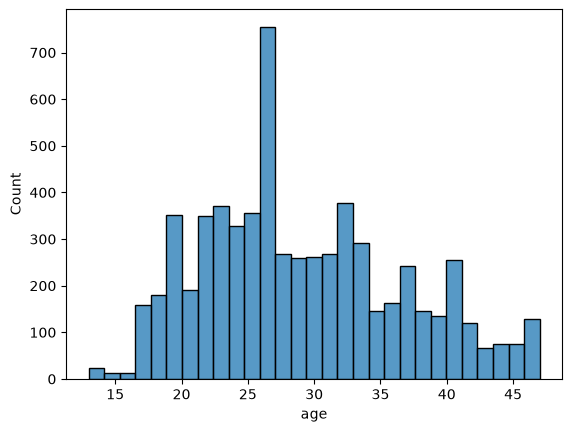

In [53]:
#Check for outliers
sns.histplot(df_alarm_survey['age'])

<Axes: ylabel='number_of_snoozes'>

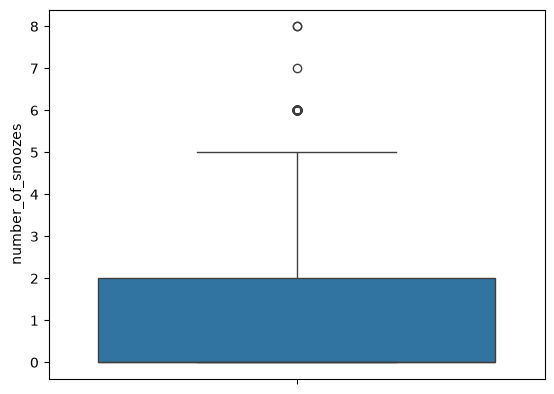

In [54]:
sns.boxplot(df_alarm_survey['number_of_snoozes'])

## 7. Create Columns From Numeric Data

* Read data into Python
* Check the data type of each column
* Create a numeric column using arithmetic
* Create a numeric column using conditional logic

In [55]:
# Create a “Total Spend” column that includes both the pen cost and shipping cost for each sale
# Create a “Free Shipping” column that says yes if the sale included free shipping, and no otherwise

In [56]:
pen_sales_file = 'Pen Sales Data.xlsx'

In [57]:
df_pen_sales = pd.read_excel(data_folder + r'\\' + pen_sales_file)

In [58]:
df_pen_sales.head(5)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Review
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,"DoodleWithMe|I love the way this pen writes, b..."
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,ScribbleMaster|The classic Sharpie marker has ...
2,5203,Ballpoint Pens (Bold),6.95,4.99,2023-05-01,2023-05-02,PenPalForever|The retractable ballpoint pen ha...
3,5204,Gel Pens,5.99,2.99,2023-05-01,2023-05-04,TheWriteWay|This gel pen has a comfortable gri...
4,5205,Rollerball Pens,12.99,1.99,2023-05-01,2023-05-03,PenAndPaperPerson|The rollerball pen has a smo...


In [59]:
df_pen_sales.dtypes

Customer                  int64
Item                        str
Pen Cost                float64
Shipping Cost           float64
Purchase Date    datetime64[us]
Delivery Date    datetime64[us]
Review                      str
dtype: object

In [60]:
df_pen_sales['Total Spend'] = df_pen_sales['Pen Cost'] + df_pen_sales['Shipping Cost']

In [61]:
df_pen_sales['Free Shipping'] = np.where(df_pen_sales['Shipping Cost'] == 0.00, 1, 0)

In [62]:
df_pen_sales.head(2)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Review,Total Spend,Free Shipping
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,"DoodleWithMe|I love the way this pen writes, b...",8.98,0
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,ScribbleMaster|The classic Sharpie marker has ...,12.99,1


## 8. Create Columns From DateTime Data

* Calculate the difference between two datetime columns and save it as a new column
* Take the average of a column

In [63]:
# Calculate the number of days between the purchase and delivery date for each sale
# Save it as a new column called “Delivery Time”
# What were the average days from purchase to delivery?

In [64]:
df_pen_sales.head(2)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Review,Total Spend,Free Shipping
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,"DoodleWithMe|I love the way this pen writes, b...",8.98,0
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,ScribbleMaster|The classic Sharpie marker has ...,12.99,1


In [65]:
df_pen_sales['Delivery Time'] = df_pen_sales['Delivery Date'] - df_pen_sales['Purchase Date']

In [66]:
df_pen_sales.head(5)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Review,Total Spend,Free Shipping,Delivery Time
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,"DoodleWithMe|I love the way this pen writes, b...",8.98,0,2 days
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,ScribbleMaster|The classic Sharpie marker has ...,12.99,1,3 days
2,5203,Ballpoint Pens (Bold),6.95,4.99,2023-05-01,2023-05-02,PenPalForever|The retractable ballpoint pen ha...,11.94,0,1 days
3,5204,Gel Pens,5.99,2.99,2023-05-01,2023-05-04,TheWriteWay|This gel pen has a comfortable gri...,8.98,0,3 days
4,5205,Rollerball Pens,12.99,1.99,2023-05-01,2023-05-03,PenAndPaperPerson|The rollerball pen has a smo...,14.98,0,2 days


In [67]:
df_pen_sales['Delivery Time'].mean()

Timedelta('3 days 05:45:36')

## 9. Create Columns From Text Data

* Split one column into multiple columns
* Create a Boolean column (True / False) to show whether a text field contains particular words

In [68]:
# Split the reviews on the “|” character to create two new columns: “User Name” and “Review Text”
# Create a “Leak or Spill” column that flags the reviews that mention either “leak” or “spill”

In [69]:
df_pen_sales.head(2)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Review,Total Spend,Free Shipping,Delivery Time
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,"DoodleWithMe|I love the way this pen writes, b...",8.98,0,2 days
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,ScribbleMaster|The classic Sharpie marker has ...,12.99,1,3 days


In [84]:
#df_pen_sales_review = df_pen_sales['Review'].str.split('|').to_list()
#Another way, this way gives you an index
df_pen_sales_review = pd.DataFrame(df_pen_sales['Review'].str.split('|').to_list())

In [85]:
#List of lists
df_pen_sales_review

,0,1
0,DoodleWithMe,"I love the way this pen writes, but unfortunat..."
1,ScribbleMaster,"The classic Sharpie marker has a bold, permane..."
2,PenPalForever,"The retractable ballpoint pen has a durable, m..."
3,TheWriteWay,This gel pen has a comfortable grip and writes...
4,PenAndPaperPerson,"The rollerball pen has a smooth, fluid feel an..."
5,SmoothOperatorPen,"This gel pen writes smoothly with a bold, vibr..."
6,InkStainedFingers,This pen is prone to leaking and can create a ...
7,BoldInkWriter,"Unfortunately, this pen has a tendency to spil..."
8,PenmanshipPro,The gel pen has a comfortable grip and writes ...
9,GelPenGuru,This retractable gel pen has a fine point that...


In [86]:
#Add 2 new columns, User Name and Reviews
df_pen_sales[['User Name', 'Reviews']] = df_pen_sales_review

In [87]:
df_pen_sales.head(3)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Review,Total Spend,Free Shipping,Delivery Time,User Name,Reviews
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,"DoodleWithMe|I love the way this pen writes, b...",8.98,0,2 days,DoodleWithMe,"I love the way this pen writes, but unfortunat..."
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,ScribbleMaster|The classic Sharpie marker has ...,12.99,1,3 days,ScribbleMaster,"The classic Sharpie marker has a bold, permane..."
2,5203,Ballpoint Pens (Bold),6.95,4.99,2023-05-01,2023-05-02,PenPalForever|The retractable ballpoint pen ha...,11.94,0,1 days,PenPalForever,"The retractable ballpoint pen has a durable, m..."


In [74]:
#Drop the older Review column
df_pen_sales = df_pen_sales.drop('Review', axis=1)

In [75]:
df_pen_sales.head(3)

,Customer,Item,Pen Cost,Shipping Cost,Purchase Date,Delivery Date,Total Spend,Free Shipping,Delivery Time,User Name,Reviews
0,5201,Ballpoint Pens,5.99,2.99,2023-05-01,2023-05-03,8.98,0,2 days,DoodleWithMe,"I love the way this pen writes, but unfortunat..."
1,5202,Sharpies,12.99,0.00,2023-05-01,2023-05-04,12.99,1,3 days,ScribbleMaster,"The classic Sharpie marker has a bold, permane..."
2,5203,Ballpoint Pens (Bold),6.95,4.99,2023-05-01,2023-05-02,11.94,0,1 days,PenPalForever,"The retractable ballpoint pen has a durable, m..."


In [78]:
#Add a column to flag Leak or Spill in Reviews
df_pen_sales['Leak_Or_Spill'] = df_pen_sales['Reviews'].str.lower().str.contains('leak|spill', regex=True)

In [83]:
#To enable full text in column
pd.set_option('display.max_colwidth', None)

In [84]:
df_pen_sales[['Reviews', 'Leak_Or_Spill']].head(5)

,Reviews,Leak_Or_Spill
0,"I love the way this pen writes, but unfortunately it has a tendency to leak if left unused for too long. It's important to keep it capped when not in use.",True
1,"The classic Sharpie marker has a bold, permanent ink that works on almost any surface. It's perfect for labeling, drawing, or writing in a variety of settings.",False
2,"The retractable ballpoint pen has a durable, metal clip and a sturdy design. It writes with a consistent flow and is a reliable choice for everyday use.",False
3,"This gel pen has a comfortable grip and writes with vibrant, consistent ink. It's perfect for taking notes or writing in a journal.",False
4,"The rollerball pen has a smooth, fluid feel and creates bold, expressive lines. It's a great option for artists and writers who want to add personality to their work.",False


In [88]:
df_pen_sales.dtypes

Customer                   int64
Item                         str
Pen Cost                 float64
Shipping Cost            float64
Purchase Date     datetime64[us]
Delivery Date     datetime64[us]
Review                       str
Total Spend              float64
Free Shipping              int64
Delivery Time    timedelta64[us]
User Name                    str
Reviews                      str
dtype: object